# Лабораторная работа №2. Моделирование гауссовского случайного процесса с заданной корреляционной функцией

**Вариант:** номер по журналу — 11, группа — 2, ПК — 4.

| Параметр | Значение |
|---|---|
| Вариант КФ | 3 (11 → 3 по кругу из 4) |
| Целевая КФ | $R(\tau) = \cos(10\tau/l)\,e^{-\frac12(\tau/l)^2}$, интервал корреляции оценивается по $R(\tau = 3l) \approx 0$ |
| $l_1$ | 4 мкс (номер ПК), второй интервал $2l_1 = 8$ мкс |
| Исходный процесс | белый гауссовский шум, $m = 0$, $\sigma = 2$ |
| Частота дискретизации | 20 МГц, интервал моделирования 300 мкс (≫ $3\cdot 2l_1 = 24$ мкс) |

СКО исходного процесса в задании не указано, поэтому взято $\sigma = 2$ (номер группы), как в ЛР1.

План работы:
1. Моделирование СП с экспоненциальной КФ $R(\tau)=e^{-|\tau|/l}$ (по шаблону).
2. Моделирование СП с КФ по варианту для $l = l_1$ и $l = 2l_1$.
3. Анализ распределений, КФ и СПМ до и после фильтра.

In [1]:
%matplotlib inline
import numpy as np
from numpy.fft import rfft, irfft, rfftfreq
from scipy import stats
import matplotlib.pyplot as plt
from scheme import draw_scheme

plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(11)

time_window_us = 300     # интервал моделирования, мкс
f_sampling_mhz = 20      # частота дискретизации, МГц
sigma_normal = 2         # СКО исходного гауссовского процесса
mu_param = 0             # математическое ожидание
l1_us = 4                # интервал корреляции l1 = номер ПК, мкс
n_acf = 10               # число усредняемых реализаций КФ
n_psd = 20               # число усредняемых реализаций СПМ (10...30)
n_counts = int(time_window_us * f_sampling_mhz)   # число отсчётов в реализации
dt_us = 1 / f_sampling_mhz

# Ось сдвигов КФ (оценка по np.correlate, mode='full') и ось частот
shift_axis_us = np.arange(-(n_counts - 1), n_counts) * dt_us
f_axis_mhz = rfftfreq(n_counts, dt_us)

## Модель формирования процесса

Белый гауссовский шум $x(t)$ с дисперсией $\sigma^2$ пропускается через линейный фильтр с комплексным коэффициентом передачи $K(f)$. Спектральная плотность мощности (СПМ) на выходе
$$S_y(f) = |K(f)|^2\, S_x(f) = |K(f)|^2\,\sigma^2\Delta t.$$
По теореме Винера — Хинчина СПМ и КФ связаны преобразованием Фурье. Чтобы выходная КФ была равна целевой $R(\tau)$, АЧХ фильтра берётся равной
$$|K(f)| = \sqrt{\mathcal{F}\{R(\tau)\}},$$
а ФЧХ — нулевой. Фильтрация выполняется в частотной области как циклическая свёртка: $y = \mathcal{F}^{-1}\{\mathcal{F}\{x\}\cdot K\}$.
В дискретном виде $\frac1N\sum_k |K_k|^2 = R(0) = 1$, поэтому дисперсия на выходе фильтра сохраняется: $D\{y\} = \sigma^2 R(0) = \sigma^2$.

Линейное преобразование гауссовского процесса оставляет его гауссовским, поэтому плотность распределения отсчётов на выходе — тоже $N(0, \sigma)$.

Для целевой КФ варианта
$$S(f) = \mathcal{F}\{\cos(\omega_0\tau)\,e^{-\tau^2/2l^2}\} = \frac{\sqrt{2\pi}\,l}{2}\left[e^{-2\pi^2 l^2 (f-f_0)^2} + e^{-2\pi^2 l^2 (f+f_0)^2}\right], \qquad f_0 = \frac{10}{2\pi l},$$
то есть СПМ — два гауссовских «горба» на частотах $\pm f_0$ (для $l_1 = 4$ мкс $f_0 = 0{,}398$ МГц, для $2l_1 = 8$ мкс $f_0 = 0{,}199$ МГц).

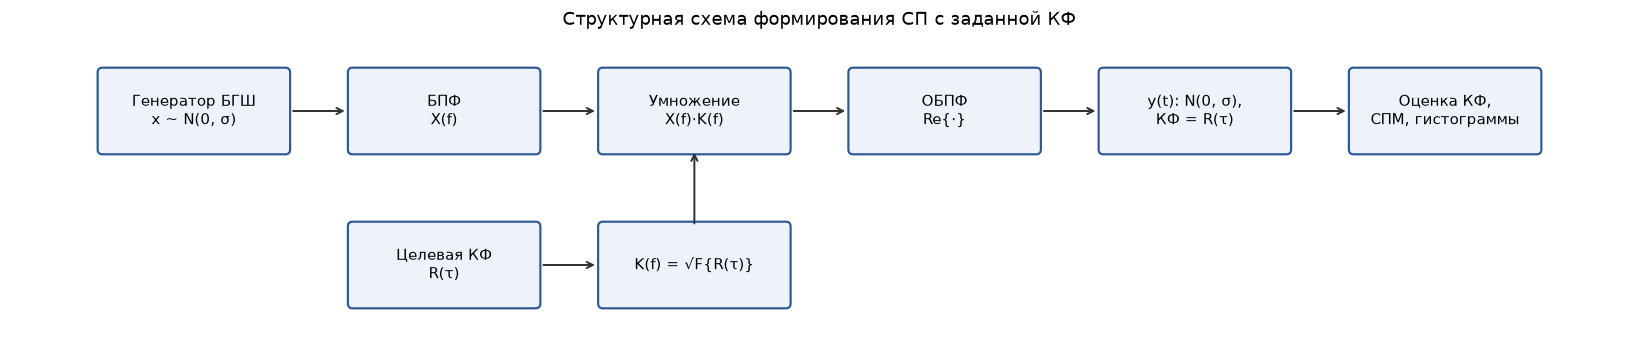

In [2]:
draw_scheme(
    blocks={
        'g':  (0, 0, 'Генератор БГШ\nx ~ N(0, σ)'),
        'f':  (2.6, 0, 'БПФ\nX(f)'),
        'k':  (5.2, 0, 'Умножение\nX(f)·K(f)'),
        'i':  (7.8, 0, 'ОБПФ\nRe{·}'),
        'y':  (10.4, 0, "y(t): N(0, σ),\nКФ = R(τ)"),
        'r':  (2.6, -1.6, 'Целевая КФ\nR(τ)'),
        'kk': (5.2, -1.6, 'K(f) = √F{R(τ)}'),
        'a':  (13.0, 0, 'Оценка КФ,\nСПМ, гистограммы'),
    },
    arrows=[('g', 'f', ''), ('f', 'k', ''), ('i', 'y', ''), ('k', 'i', ''),
            ('r', 'kk', ''), ('kk', 'k', ''), ('y', 'a', '')],
    title='Структурная схема формирования СП с заданной КФ', size=(15, 4));

## Функции фильтра и оценки характеристик

Оценка нормированной КФ одной реализации: $\hat R(n) = \dfrac{1}{N\hat\sigma^2}\sum_k x_k x_{k+n}$. Затем оценки усредняются по реализациям.
Оценка СПМ — периодограмма $\hat S(f) = |X(f)|^2\,\Delta t/N$, усреднённая по реализациям.

In [3]:
def corr_filter(sig, acf_fun, dt):
    """Фильтр, формирующий из белого шума процесс с КФ acf_fun(τ) (циклическая свёртка через БПФ)."""
    n = sig.shape[-1]
    tau = (np.arange(n) - n // 2) * dt               # ось τ, центрированная на нуле
    r = np.fft.ifftshift(acf_fun(tau))               # R(τ), τ = 0 в первом отсчёте
    psd = np.clip(rfft(r).real, 0, None)             # F{R(τ)} — СПМ (отрицательные значения из-за усечения обнуляются)
    k = np.sqrt(psd)                                 # АЧХ фильтра, ФЧХ = 0
    return irfft(rfft(sig, axis=-1) * k, n, axis=-1)


def acf_estimate(sig):
    """Нормированная (R(0)=1) оценка КФ каждой реализации (строки массива)."""
    n = sig.shape[-1]
    return np.array([np.correlate(s, s, mode='full') / np.var(s) / n for s in sig])


def psd_estimate(sig, dt):
    """Периодограмма, усреднённая по реализациям (односторонняя), ед.²/МГц."""
    n = sig.shape[-1]
    p = np.abs(rfft(sig, axis=-1))**2 * dt / n
    p[:, 1:-1] *= 2
    return p.mean(axis=0)


def psd_theory(acf_fun, sigma, n, dt):
    """Теоретическая односторонняя СПМ процесса с дисперсией σ² и КФ acf_fun."""
    tau = (np.arange(n) - n // 2) * dt
    s = np.clip(rfft(np.fft.ifftshift(acf_fun(tau))).real, 0, None) * sigma**2 * dt
    s[1:-1] *= 2
    return s


def hist_with_gauss(samples, labels, title, ax):
    edges = np.linspace(-4.5 * sigma_normal, 4.5 * sigma_normal, 61)
    centers = (edges[:-1] + edges[1:]) / 2
    for s, lab in zip(samples, labels):
        ax.hist(s.ravel(), bins=edges, density=True, histtype='stepfilled', alpha=0.35, label=lab)
    ax.plot(centers, stats.norm.pdf(centers, mu_param, sigma_normal), 'r-', lw=2,
            label=f'N(m={mu_param}, σ={sigma_normal})')
    ax.set(title=title, xlabel='x', ylabel='W(x)')
    ax.legend()

## 1. Исходный процесс (белый гауссовский шум)

Оценка исходного процесса: m = -0.0012, σ = 2.0017


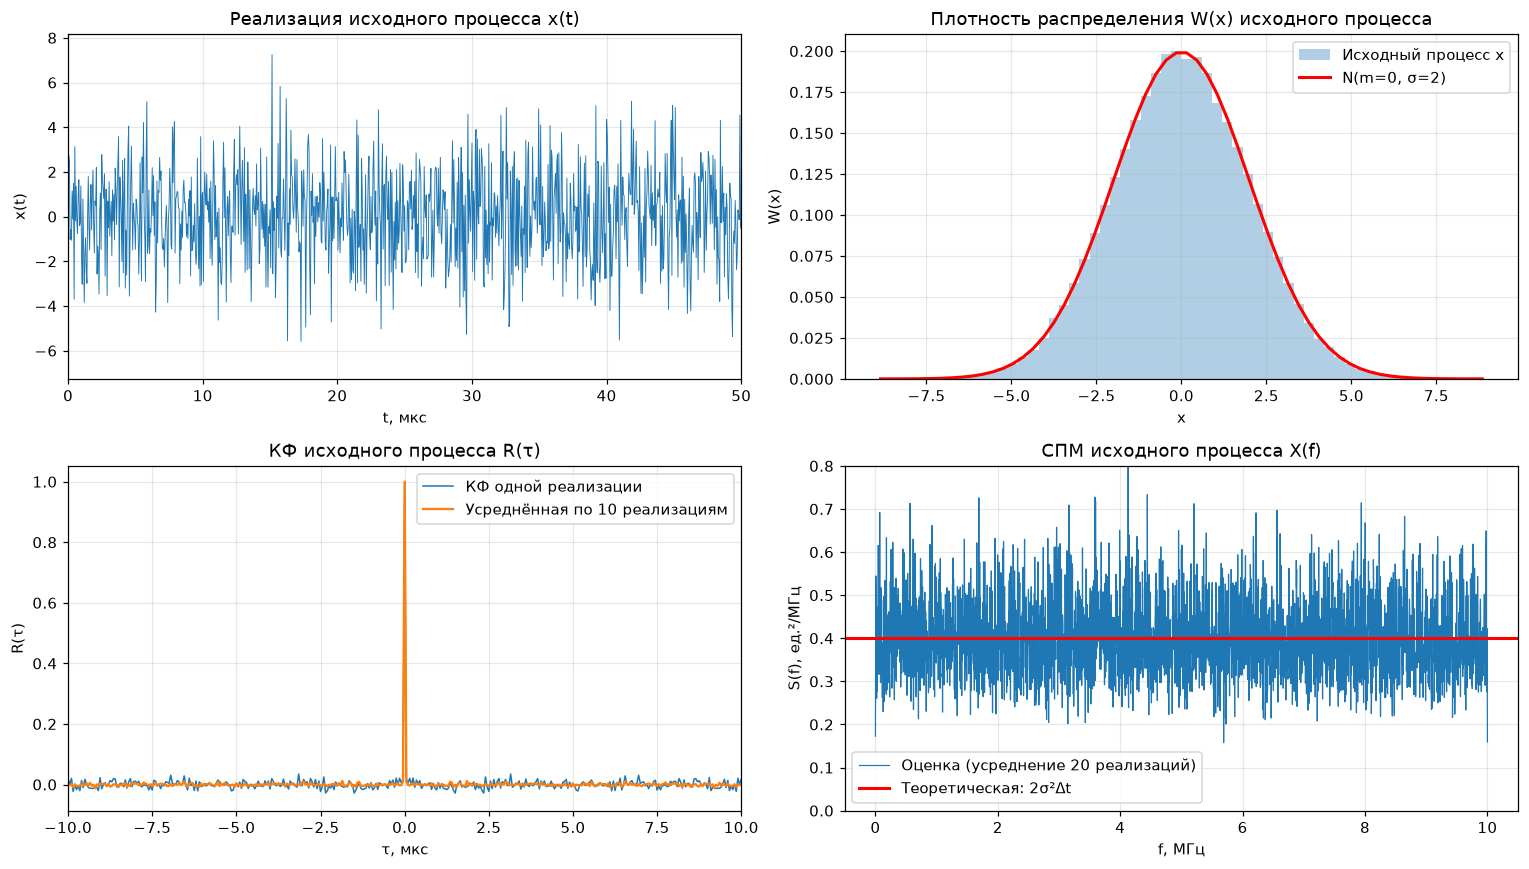

In [4]:
x = rng.normal(mu_param, sigma_normal, (n_psd, n_counts))   # исходные реализации
t_axis_us = np.arange(n_counts) * dt_us

rx = acf_estimate(x[:n_acf])
print(f'Оценка исходного процесса: m = {x.mean():.4f}, σ = {x.std():.4f}')

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
axs[0, 0].plot(t_axis_us, x[0], lw=0.6)
axs[0, 0].set(title='Реализация исходного процесса x(t)', xlabel='t, мкс', ylabel='x(t)', xlim=(0, 50))

hist_with_gauss([x], ['Исходный процесс x'], f'Плотность распределения W(x) исходного процесса', axs[0, 1])

axs[1, 0].plot(shift_axis_us, rx[0], lw=1, label='КФ одной реализации')
axs[1, 0].plot(shift_axis_us, rx.mean(axis=0), lw=1.5, label=f'Усреднённая по {n_acf} реализациям')
axs[1, 0].set(title='КФ исходного процесса R(τ)', xlabel='τ, мкс', ylabel='R(τ)', xlim=(-10, 10))
axs[1, 0].legend()

axs[1, 1].plot(f_axis_mhz, psd_estimate(x, dt_us), lw=0.8, label=f'Оценка (усреднение {n_psd} реализаций)')
axs[1, 1].axhline(2 * sigma_normal**2 * dt_us, color='r', lw=2, label='Теоретическая: 2σ²Δt')
axs[1, 1].set(title='СПМ исходного процесса X(f)', xlabel='f, МГц', ylabel='S(f), ед.²/МГц', ylim=(0, 0.8))
axs[1, 1].legend()
plt.tight_layout()

## 2. СП с экспоненциальной КФ $R(\tau) = e^{-|\tau|/l}$, $l = l_1 = 4$ мкс

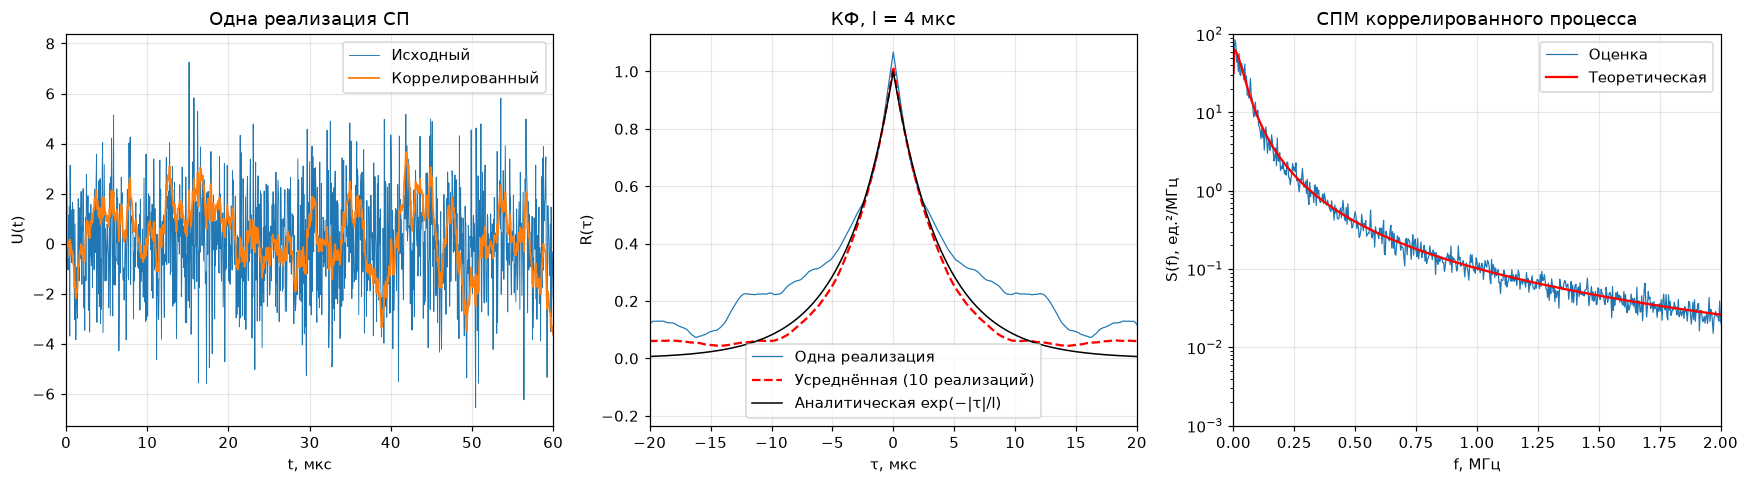

In [5]:
exp_acf = lambda tau, l=l1_us: np.exp(-np.abs(tau) / l)

y_exp = corr_filter(x, exp_acf, dt_us)
ry_exp = acf_estimate(y_exp[:n_acf])

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(t_axis_us, x[0], lw=0.6, label='Исходный')
axs[0].plot(t_axis_us, y_exp[0], lw=1.2, label='Коррелированный')
axs[0].set(title='Одна реализация СП', xlabel='t, мкс', ylabel='U(t)', xlim=(0, 60))
axs[0].legend()

axs[1].plot(shift_axis_us, ry_exp[0], lw=0.8, label='Одна реализация')
axs[1].plot(shift_axis_us, ry_exp.mean(axis=0), 'r--', lw=1.5, label=f'Усреднённая ({n_acf} реализаций)')
axs[1].plot(shift_axis_us, exp_acf(shift_axis_us), 'k-', lw=1, label='Аналитическая exp(−|τ|/l)')
axs[1].set(title=f'КФ, l = {l1_us} мкс', xlabel='τ, мкс', ylabel='R(τ)', xlim=(-5 * l1_us, 5 * l1_us))
axs[1].legend()

axs[2].semilogy(f_axis_mhz, psd_estimate(y_exp, dt_us), lw=0.8, label='Оценка')
axs[2].semilogy(f_axis_mhz, psd_theory(exp_acf, sigma_normal, n_counts, dt_us), 'r', lw=1.5, label='Теоретическая')
axs[2].set(title='СПМ коррелированного процесса', xlabel='f, МГц', ylabel='S(f), ед.²/МГц', xlim=(0, 2), ylim=(1e-3, 100))
axs[2].legend()
plt.tight_layout()

## 3. СП с КФ по варианту: $R(\tau)=\cos(10\tau/l)\,e^{-\frac12(\tau/l)^2}$, $l = l_1$ и $l = 2l_1$

In [6]:
def target_acf(tau, l):
    return np.cos(10 * tau / l) * np.exp(-0.5 * (tau / l)**2)


ls = {f'l = l₁ = {l1_us} мкс': l1_us, f'l = 2l₁ = {2 * l1_us} мкс': 2 * l1_us}
results = {}
for name, l in ls.items():
    acf = lambda tau, l=l: target_acf(tau, l)
    y = corr_filter(x, acf, dt_us)
    results[name] = dict(l=l, acf=acf, y=y, ry=acf_estimate(y[:n_acf]))
    print(f'{name}: m = {y.mean():.4f}, σ = {y.std():.4f}, R(3l) = {target_acf(3 * l, l):.4f}, '
          f'f0 = {10 / (2 * np.pi * l):.3f} МГц')

l = l₁ = 4 мкс: m = -0.0000, σ = 2.0148, R(3l) = 0.0017, f0 = 0.398 МГц
l = 2l₁ = 8 мкс: m = -0.0000, σ = 1.9063, R(3l) = 0.0017, f0 = 0.199 МГц


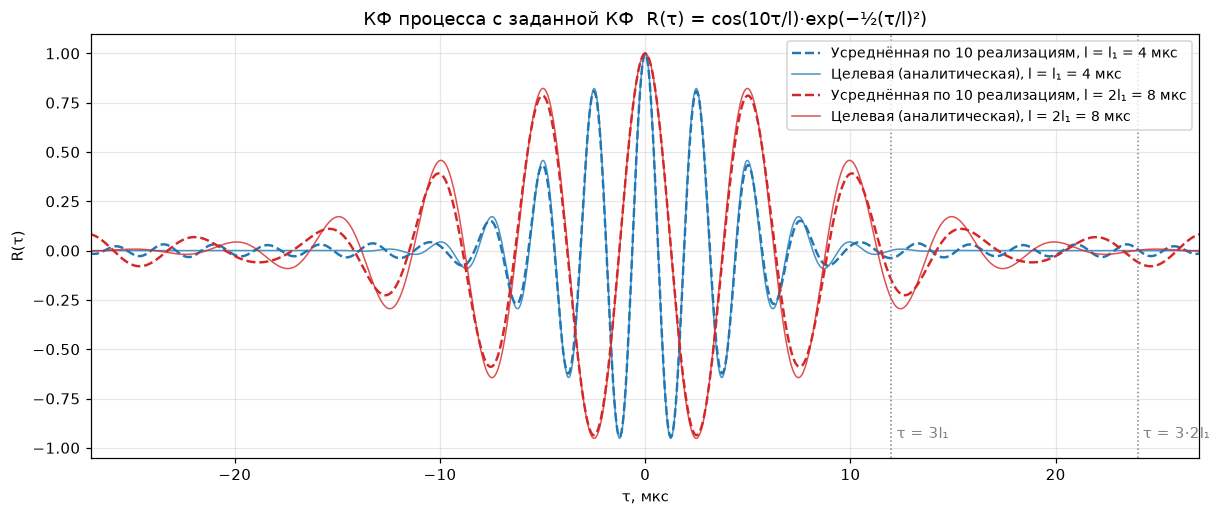

In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
styles = [('C0', 'C0'), ('C3', 'C3')]
for (name, r), (c1, c2) in zip(results.items(), styles):
    ax.plot(shift_axis_us, r['ry'].mean(axis=0), '--', color=c1, lw=1.6,
            label=f'Усреднённая по {n_acf} реализациям, {name}')
    ax.plot(shift_axis_us, r['acf'](shift_axis_us), '-', color=c2, lw=1, alpha=0.8,
            label=f'Целевая (аналитическая), {name}')
for name, r in results.items():
    ax.axvline(3 * r['l'], color='gray', ls=':', lw=1)
ax.set(title='КФ процесса с заданной КФ  R(τ) = cos(10τ/l)·exp(−½(τ/l)²)',
       xlabel='τ, мкс', ylabel='R(τ)', xlim=(-3 * 2 * l1_us - 3, 3 * 2 * l1_us + 3))
ax.text(3 * l1_us, -0.95, ' τ = 3l₁', color='gray')
ax.text(6 * l1_us, -0.95, ' τ = 3·2l₁', color='gray')
ax.legend(loc='upper right', fontsize=9);

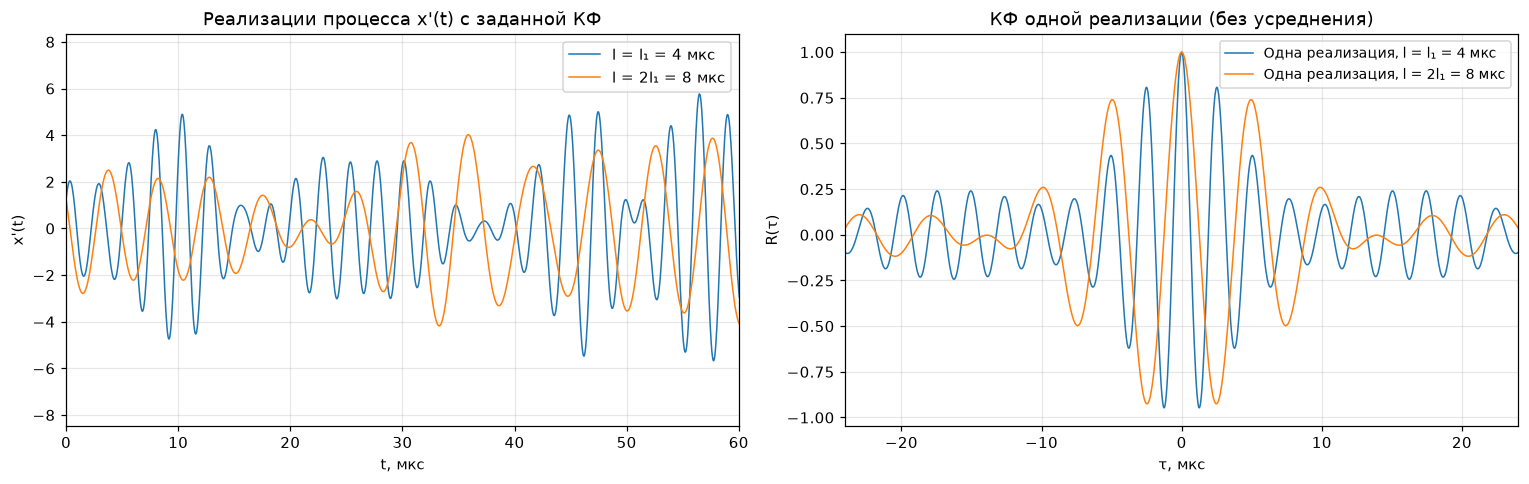

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in results.items():
    axs[0].plot(t_axis_us, r['y'][0], lw=1, label=name)
axs[0].set(title="Реализации процесса x'(t) с заданной КФ", xlabel='t, мкс', ylabel="x'(t)", xlim=(0, 60))
axs[0].legend()

for name, r in results.items():
    axs[1].plot(shift_axis_us, r['ry'][0], lw=1, label=f'Одна реализация, {name}')
axs[1].set(title='КФ одной реализации (без усреднения)', xlabel='τ, мкс', ylabel='R(τ)', xlim=(-24, 24))
axs[1].legend(fontsize=9)
plt.tight_layout()

### Плотность распределения отсчётов до и после фильтра

l = l₁ = 4 мкс: критерий Колмогорова — Смирнова (прореженная выборка) D = 0.0112, p = 0.578
l = 2l₁ = 8 мкс: критерий Колмогорова — Смирнова (прореженная выборка) D = 0.0129, p = 0.397


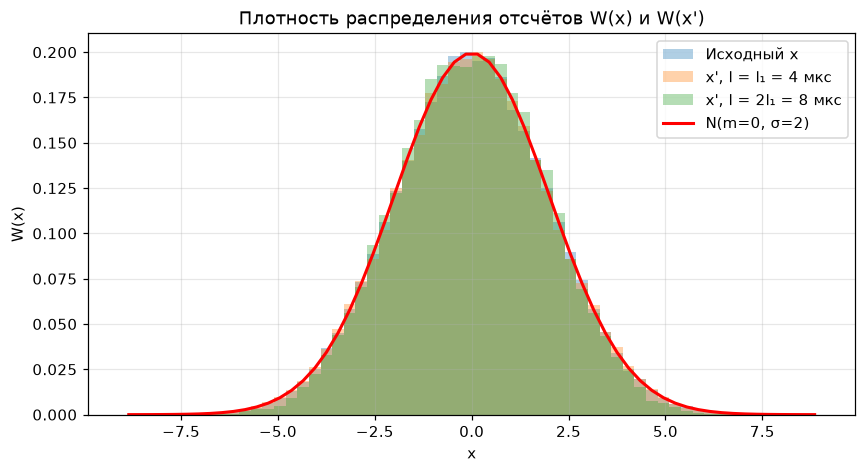

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hist_with_gauss([x] + [r['y'] for r in results.values()],
                ['Исходный x'] + [f"x', {n}" for n in results],
                "Плотность распределения отсчётов W(x) и W(x')", ax)
for name, r in results.items():
    ks = stats.kstest(r['y'].ravel()[::25], lambda v: stats.norm.cdf(v, mu_param, sigma_normal))
    print(f"{name}: критерий Колмогорова — Смирнова (прореженная выборка) D = {ks.statistic:.4f}, p = {ks.pvalue:.3f}")

### СПМ процесса с заданной КФ

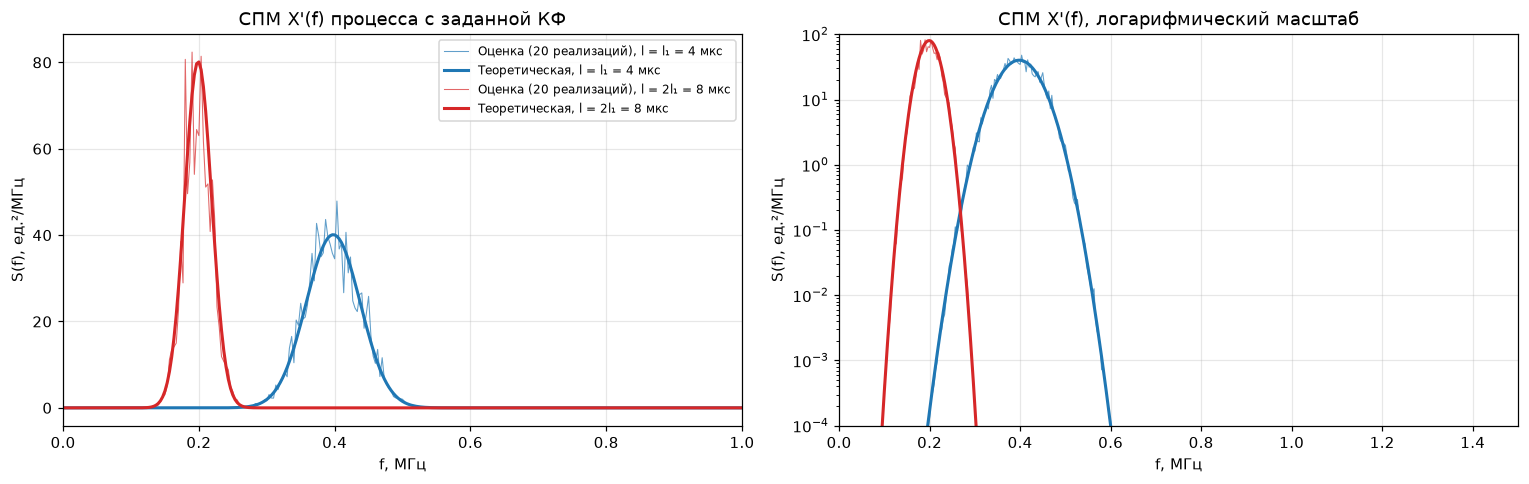

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for (name, r), c in zip(results.items(), ['C0', 'C3']):
    for ax in axs:
        ax.plot(f_axis_mhz, psd_estimate(r['y'], dt_us), color=c, lw=0.7, alpha=0.7,
                label=f'Оценка ({n_psd} реализаций), {name}')
        ax.plot(f_axis_mhz, psd_theory(r['acf'], sigma_normal, n_counts, dt_us), color=c, lw=2,
                label=f'Теоретическая, {name}')
axs[0].set(title="СПМ X'(f) процесса с заданной КФ", xlabel='f, МГц', ylabel='S(f), ед.²/МГц', xlim=(0, 1))
axs[1].set(title="СПМ X'(f), логарифмический масштаб", xlabel='f, МГц', ylabel='S(f), ед.²/МГц',
           xlim=(0, 1.5), yscale='log', ylim=(1e-4, 100))
axs[0].legend(fontsize=8)
plt.tight_layout()

## 4. Корреляционная и ковариационная функции

Чтобы показать разницу, к процессу с КФ варианта ($l = l_1$) добавлено постоянное среднее $m = 3$.
- **Корреляционная функция** (без вычитания среднего): $B(\tau) = M\{x(t)\,x(t-\tau)\} = \sigma^2 R(\tau) + m^2$.
- **Ковариационная функция** (с вычитанием среднего): $K(\tau) = M\{(x(t)-m)(x(t-\tau)-m)\} = \sigma^2 R(\tau)$.

Обе нормированы на $\sigma^2$.

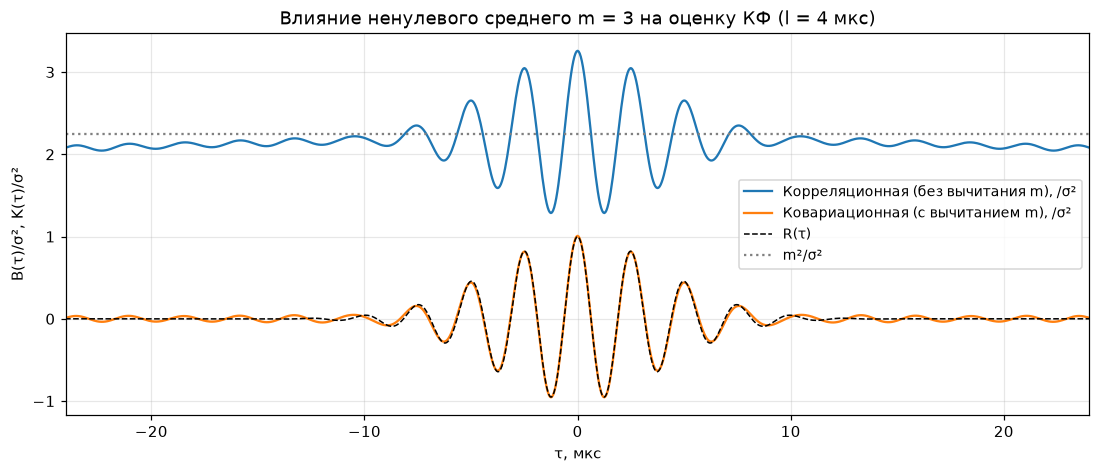

In [11]:
m_demo = 3
r1 = results[list(results)[0]]
y_m = r1['y'][:n_acf] + m_demo
n = n_counts
corr = np.mean([np.correlate(s, s, 'full') / n for s in y_m], axis=0) / sigma_normal**2
cov = np.mean([np.correlate(s - s.mean(), s - s.mean(), 'full') / n for s in y_m], axis=0) / sigma_normal**2

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(shift_axis_us, corr, lw=1.5, label='Корреляционная (без вычитания m), /σ²')
ax.plot(shift_axis_us, cov, lw=1.5, label='Ковариационная (с вычитанием m), /σ²')
ax.plot(shift_axis_us, r1['acf'](shift_axis_us), 'k--', lw=1, label='R(τ)')
ax.axhline(m_demo**2 / sigma_normal**2, color='gray', ls=':', label='m²/σ²')
ax.set(title=f'Влияние ненулевого среднего m = {m_demo} на оценку КФ (l = {l1_us} мкс)',
       xlabel='τ, мкс', ylabel='B(τ)/σ², K(τ)/σ²', xlim=(-24, 24))
ax.legend(fontsize=9);

## Выводы

1. **Что сделано.** Белый гауссовский шум $N(0, 2)$ пропущен через формирующий фильтр с АЧХ $|K(f)|=\sqrt{\mathcal F\{R(\tau)\}}$ и нулевой ФЧХ. Получены процессы с экспоненциальной КФ и с КФ варианта $R(\tau)=\cos(10\tau/l)e^{-\frac12(\tau/l)^2}$ для $l=4$ и $8$ мкс. Усреднённые по 10 реализациям оценки КФ совпадают с целевыми функциями. Остаточные флуктуации оценок порядка $\sqrt{l/T}$, они уменьшаются с ростом числа реализаций и длительности интервала моделирования. Оценки СПМ, усреднённые по 20 реализациям, совпадают с теоретическими: исходный шум имеет равномерную СПМ, процесс по варианту — два гауссовских максимума на $\pm f_0$.
2. **Распределение отсчётов.** Гистограммы до и после фильтра совпадают с $N(0,2)$: линейная фильтрация гауссовского процесса сохраняет гауссовость, а нормировка АЧХ ($R(0)=1$) сохраняет дисперсию. Фильтр меняет только связь между соседними отсчётами, но не одномерное распределение.
3. **К какой функции сходится оценка.** Использованная оценка $\frac{1}{N\hat\sigma^2}\sum x_k x_{k+n}$ без вычитания среднего — это корреляционная функция. При $m=0$ она совпадает с ковариационной, и моделирование сходится к ковариационной (нормированной) функции $R(\tau)$. При $m\ne0$ разница видна в разделе 4: корреляционная функция $B(\tau)=\sigma^2R(\tau)+m^2$ при больших $\tau$ стремится к $m^2$, а не к нулю. Ковариационная функция $K(\tau)=\sigma^2R(\tau)$ описывает только статистическую связь флуктуаций и затухает до нуля. Кроме того, смещённая оценка с делителем $N$ содержит множитель $(1-|\tau|/T)$, но при $T=300$ мкс ≫ $l$ он пренебрежимо мал.
4. **Влияние параметра $l$.** При увеличении $l$ с 4 до 8 мкс КФ растягивается по оси $\tau$ в 2 раза: огибающая $e^{-\frac12(\tau/l)^2}$ затухает медленнее (до $R\approx0$ при $\tau = 3l$: 12 и 24 мкс), а период осцилляций $2\pi l/10$ растёт с 2,5 до 5 мкс. Соответственно СПМ сжимается в 2 раза: центральная частота $f_0=10/(2\pi l)$ уменьшается с 0,40 до 0,20 МГц, ширина «горбов» уменьшается вдвое, а их высота растёт вдвое (площадь, то есть мощность $\sigma^2$, сохраняется). Во временной области процесс с большим $l$ становится более узкополосным и медленнее меняется: соседние отсчёты связаны на большем интервале времени.